# Comparación final y decisión

En este capítulo elegimos un modelo por dominio. La elección no sale solo de la métrica principal: ponderamos desempeño, robustez, equidad o calibración, latencia y costo, justificamos los pesos, comprobamos si la decisión cambia al moverlos y estimamos el costo de operar cada opción.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from project.book_utils import CAT, MUTED, ci, exists, need, style

style()
pd.set_option("display.precision", 3)
md = lambda t: display(Markdown(t))  # noqa: E731


DEC = need("analysis/decision/decision.pkl")


def show_decision(res, labels):
    if res.get("missing_criteria"):
        md("Criterios sin medición para ningún modelo, excluidos con renormalización de los pesos restantes: "
           + ", ".join(res["missing_criteria"]) + ".")
    if res["winner"] is None:
        md("Menos de dos modelos tienen todos los criterios medidos; el análisis multicriterio de este dominio no se puede calcular.")
        return
    N, w = res["normalized"], res["weights"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 0.45 * len(N) + 1.8), gridspec_kw=dict(width_ratios=[1.5, 1]))
    axes[0].imshow(N.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
    axes[0].set_yticks(range(len(N)), [labels.get(m, m) for m in N.index])
    axes[0].set_xticks(range(N.shape[1]), [f"{c}\n(peso {w[c]:.2f})" for c in N.columns], fontsize=8)
    for (a, b), v in np.ndenumerate(N.to_numpy()):
        axes[0].text(b, a, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.6 else "black")
    axes[0].grid(False)
    sc = res["score"]
    axes[1].barh([labels.get(m, m) for m in sc.index], sc.values, color=[CAT[0] if m == res["winner"] else MUTED for m in sc.index])
    axes[1].invert_yaxis(); axes[1].set(xlabel="puntaje ponderado")
    plt.show()
    md(f"Ganador con los pesos de referencia: **{labels.get(res['winner'], res['winner'])}**. Con 5000 vectores de pesos muestreados de una "
       f"Dirichlet centrada en los de referencia, gana en el {100 * res['dirichlet'].get(res['winner'], 0):.0f} % de los casos"
       + ("" if len(res["dirichlet"]) == 1 else "; el resto de las veces gana " + ", ".join(
           f"{labels.get(m, m)} ({100 * p:.0f} %)" for m, p in res["dirichlet"].items() if m != res["winner"])) + ".")
    ch = res["oat"][res["oat"].ganador != res["winner"]]
    md("Variando un peso a la vez (×0.5 y ×1.5), el ganador no cambia." if ch.empty else
       "Variando un peso a la vez, el ganador cambia en: " + "; ".join(
           f"{r.criterio} ×{r.factor} → {labels.get(r.ganador, r.ganador)}" for r in ch.itertuples()) + ".")

## Segmentación

**Criterios y pesos.** El uso previsto es medir poblaciones celulares en experimentos de laboratorio, donde un conteo o una morfometría sesgados invalidan el experimento y la inferencia no necesita tiempo real.

| Criterio | Medida | Peso | Justificación |
|---|---|---|---|
| Desempeño | AP@[.5:.95] medio en test | 0.40 | Es la métrica pre-registrada y la que refleja el uso práctico |
| Peor tipo celular | AP del tipo celular con menor AP | 0.25 | Un laboratorio trabaja con una línea a la vez: el modelo debe servir para cada una, no solo en promedio |
| Latencia | p50 por imagen | 0.15 | Afecta al lote diario de imágenes, no a una decisión en línea |
| Costo de entrenamiento | horas de GPU por semilla | 0.10 | Determina el costo de cada reentrenamiento |
| Tamaño | parámetros | 0.10 | Memoria y facilidad de despliegue en el equipo del laboratorio |

,AP,peor tipo,latencia,horas de GPU,parámetros
model,,,,,
Cellpose ajustado,0.253,0.117,478.717,0.381,6.601e+06
Mask R-CNN,0.228,0.099,439.164,1.161,4.588e+07
U-Net++,0.214,0.077,408.792,0.774,9.053e+06
SAM (cajas),0.191,0.082,720.711,1.161,1.396e+08
Hover (NP+HV),0.096,0.028,201.567,0.686,9.053e+06
Cellpose cero-shot,0.094,0.074,1296.667,0.000,6.601e+06
SAM automático,0.025,0.022,12696.368,0.000,9.374e+07
Otsu + watershed,0.010,0.002,124.858,0.000,0.000e+00


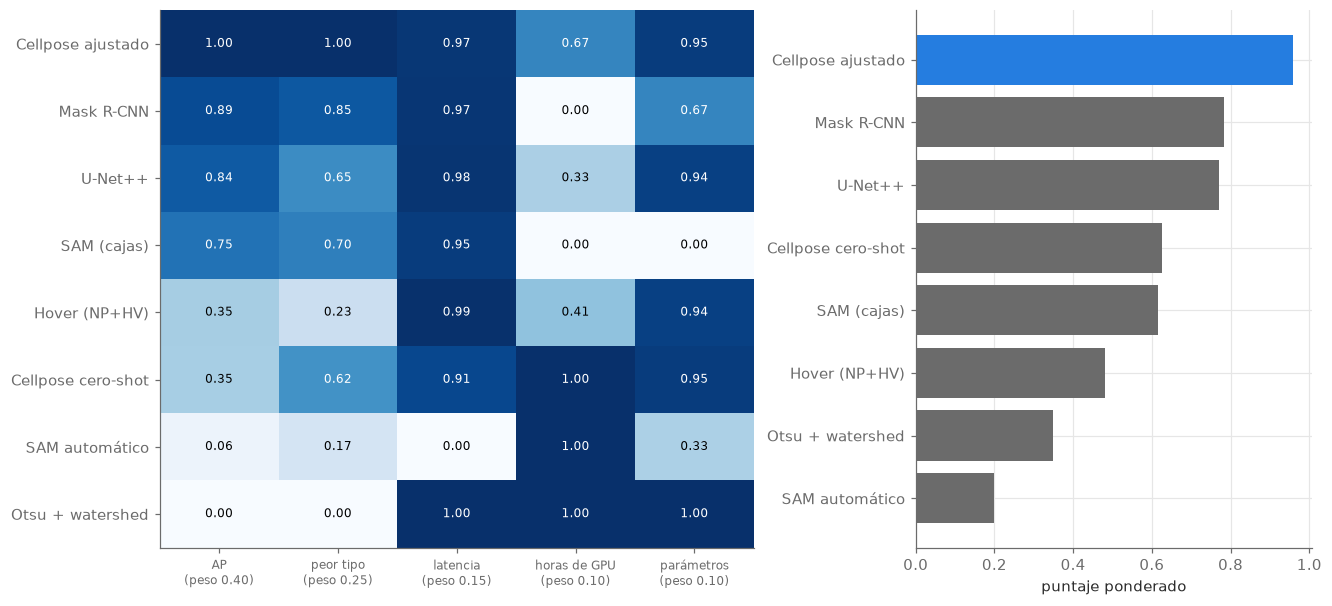

Ganador con los pesos de referencia: **Cellpose ajustado**. Con 5000 vectores de pesos muestreados de una Dirichlet centrada en los de referencia, gana en el 100 % de los casos.

Variando un peso a la vez (×0.5 y ×1.5), el ganador no cambia.

In [2]:
S = need("analysis/seg_stats/stats.pkl")
L = S["labels"]
SUM = S["summary"]
rseg = DEC["seg"]
display(rseg["table"].rename(index=L))
if rseg["excluded"]:
    md("Quedan fuera del análisis multicriterio por falta de algún criterio medido: " + ", ".join(L.get(m, m) for m in rseg["excluded"]) + ".")
show_decision(rseg, L)

Los modelos de cero disparos (Cellpose sin ajuste, SAM) tienen costo de entrenamiento nulo en este proyecto, pero su preentrenamiento lo pagó otro: el criterio mide el costo de **nuestro** reentrenamiento, que es el que se repite en producción. La robustez a perturbaciones de imagen solo la medimos en U-Net++ y Mask R-CNN (capítulo {doc}`14_seg_ablaciones_robustez`), así que no entra en la ponderación.

In [3]:
best_seg = rseg["winner"] or SUM.ap.idxmax()  # sin análisis multicriterio: mayor AP
md(f"**Decisión de segmentación: {L.get(best_seg, best_seg)}**, con AP en test {ci(SUM.ap[best_seg], SUM.ap_lo[best_seg], SUM.ap_hi[best_seg])}.")
if exists("mlops/export_seg/export_seg.pkl"):
    _srv = need("mlops/export_seg/export_seg.pkl")["model"]
    if _srv != best_seg:
        md(f"El servicio del capítulo {{doc}}`30_mlops` sirve **{L.get(_srv, _srv)}**, no el ganador multicriterio. La ruta de "
           "exportación (Keras → ONNX, comprobación de paridad y cuantización) se diseñó para las redes de Keras y se ejecutó antes "
           "de medir la latencia controlada de Cellpose y SAM, que completó los criterios del análisis. Las dos decisiones responden "
           "a preguntas distintas: la exportación mide si un modelo se puede servir con las garantías declaradas, y el análisis "
           f"multicriterio cuál conviene. {L.get(best_seg, best_seg)} queda como candidato para la siguiente versión del servicio, "
           f"con la misma batería de paridad, conjunto dorado y despliegue en sombra; mientras tanto, {L.get(_srv, _srv)} cuesta "
           f"{SUM.ap[best_seg] - SUM.ap[_srv]:.3f} de AP en test frente a él.")
cmp = S.get("comparisons", {}).get("pairwise")
if cmp is not None and len(cmp):
    c = cmp[(cmp.A == best_seg) | (cmp.B == best_seg)].copy()
    c["rival"] = np.where(c.A == best_seg, c.B, c.A).astype(str)
    c["diferencia"] = np.where(c.A == best_seg, c.mean_diff, -c.mean_diff)
    c["IC 95 %"] = [f"[{lo:.3f}, {hi:.3f}]" if a == best_seg else f"[{-hi:.3f}, {-lo:.3f}]" for a, lo, hi in zip(c.A, c.diff_lo, c.diff_hi)]
    display(c[["rival", "diferencia", "IC 95 %", "p_holm", "relevante"]].assign(rival=lambda d: d.rival.map(lambda m: L.get(m, m)))
            .rename(columns={"diferencia": f"AP {L.get(best_seg, best_seg)} − rival", "p_holm": "p (Holm)", "relevante": "significativa y ≥ 0.02"})
            .style.hide(axis="index").format(precision=3))

**Decisión de segmentación: Cellpose ajustado**, con AP en test 0.253 [0.226, 0.281].

El servicio del capítulo {doc}`30_mlops` sirve **U-Net++**, no el ganador multicriterio. La ruta de exportación (Keras → ONNX, comprobación de paridad y cuantización) se diseñó para las redes de Keras y se ejecutó antes de medir la latencia controlada de Cellpose y SAM, que completó los criterios del análisis. Las dos decisiones responden a preguntas distintas: la exportación mide si un modelo se puede servir con las garantías declaradas, y el análisis multicriterio cuál conviene. Cellpose ajustado queda como candidato para la siguiente versión del servicio, con la misma batería de paridad, conjunto dorado y despliegue en sombra; mientras tanto, U-Net++ cuesta 0.039 de AP en test frente a él.

rival,AP Cellpose ajustado − rival,IC 95 %,p (Holm),significativa y ≥ 0.02
U-Net++,0.039,"[0.032, 0.046]",0.000,True
Hover (NP+HV),0.158,"[0.138, 0.179]",0.000,True
Mask R-CNN,0.026,"[0.017, 0.034]",0.000,True
Cellpose cero-shot,0.159,"[0.127, 0.192]",0.000,True
SAM (cajas),0.062,"[0.050, 0.073]",0.000,True
SAM automático,0.229,"[0.202, 0.256]",0.000,True
Otsu + watershed,0.243,"[0.215, 0.271]",0.000,True


## Clasificación de texto

**Criterios y pesos.** El uso previsto es sugerir categorías a una persona que organiza candidaturas (capítulo {doc}`25_nlp_analisis_critico`). Los errores afectan a personas, así que la equidad y la robustez pesan más que en segmentación.

| Criterio | Medida | Peso | Justificación |
|---|---|---|---|
| Desempeño | F1 macro media en test | 0.35 | Métrica pre-registrada; trata por igual a las 24 profesiones |
| Equidad | tasa de cambio de predicción en el contrafactual de género | 0.20 | Una predicción que cambia con el género gramatical es inaceptable en selección de personal |
| Robustez | caída media de F1 macro en las perturbaciones sin atajo (*typos*, mayúsculas, minúsculas, sin geografía, primeras 200 palabras) | 0.15 | Currículos reales llegan con errores y formatos variados |
| Calibración | ECE en test | 0.10 | Las probabilidades se muestran a la persona y alimentan la derivación por confianza |
| Latencia | p50 en CPU por documento | 0.10 | Servicio en línea sin GPU |
| Costo de entrenamiento | segundos por semilla | 0.10 | Determina el costo de cada reentrenamiento |

,F1,cambio por género,caída por perturbación,ECE,latencia,segundos
model,,,,,,
DistilBERT,0.774,0.000,0.010,0.088,257.318,141.827
CNN-1D,0.766,0.000,0.015,0.043,11.560,20.772
TF-IDF + XGBoost,0.730,0.003,0.020,0.064,6.885,217.933
NB-SVM,0.704,0.003,0.009,0.057,2.740,11.749
BiLSTM,0.700,0.003,0.005,0.075,159.628,199.903
TF-IDF + RL,0.660,0.000,0.003,0.069,2.827,11.073
FastText,0.450,0.003,0.010,0.081,1.088,49.976


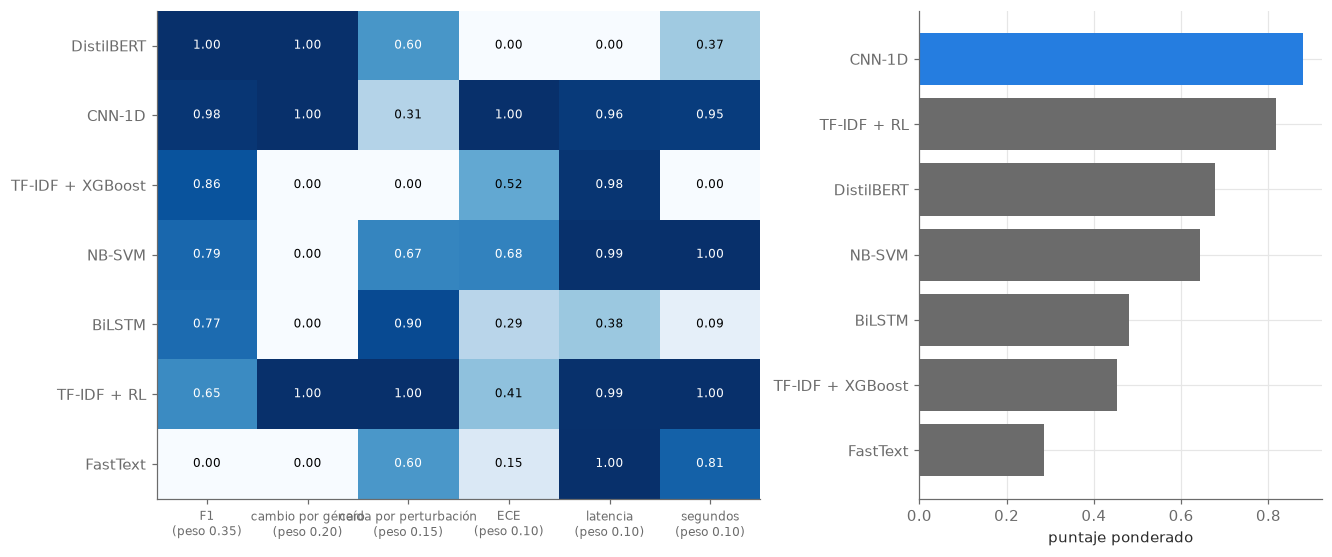

Ganador con los pesos de referencia: **CNN-1D**. Con 5000 vectores de pesos muestreados de una Dirichlet centrada en los de referencia, gana en el 79 % de los casos; el resto de las veces gana TF-IDF + RL (21 %), DistilBERT (0 %).

Variando un peso a la vez (×0.5 y ×1.5), el ganador no cambia.

In [4]:
N_ = need("analysis/nlp_stats/stats.pkl")
LN = N_["labels"]
T = N_["results"].drop("majority", errors="ignore")
rtxt = DEC["txt"]
display(rtxt["table"].rename(index=LN))
if rtxt["excluded"]:
    md("Quedan fuera del análisis multicriterio por falta de algún criterio medido: " + ", ".join(LN.get(m, m) for m in rtxt["excluded"]) + ".")
show_decision(rtxt, LN)

In [5]:
best_txt = rtxt["winner"] or T.f1_macro.idxmax()  # sin análisis multicriterio: mayor F1
md(f"**Decisión de texto (multicriterio): {LN.get(best_txt, best_txt)}**, con F1 macro en test {T.f1_macro[best_txt]:.3f} ± {T.f1_macro_sd[best_txt]:.3f} "
   f"(voto de semillas {ci(T.f1_vote[best_txt], T.f1_vote_lo[best_txt], T.f1_vote_hi[best_txt])}).")
if exists("mlops/export_text/export_text.pkl"):
    et = need("mlops/export_text/export_text.pkl")
    md(f"La regla de servicio pre-registrada (DistilBERT solo si supera a TF-IDF + RL en validación por más de δ = 0.02) eligió **{LN.get(et['choice'], et['choice'])}**. "
       + ("Las dos decisiones coinciden." if et["choice"] == best_txt else
          "Las dos decisiones no coinciden: la regla de servicio solo compara dos candidatos por F1 de validación, y el análisis multicriterio "
          "pondera seis criterios sobre todos los modelos. Mantenemos en producción el modelo de la regla pre-registrada y dejamos el ganador "
          "multicriterio como candidato para la siguiente versión, a validar con el despliegue en sombra del capítulo {doc}`31_monitoreo_deriva`."))

**Decisión de texto (multicriterio): CNN-1D**, con F1 macro en test 0.766 ± 0.013 (voto de semillas 0.779 [0.734, 0.814]).

La regla de servicio pre-registrada (DistilBERT solo si supera a TF-IDF + RL en validación por más de δ = 0.02) eligió **DistilBERT**. Las dos decisiones no coinciden: la regla de servicio solo compara dos candidatos por F1 de validación, y el análisis multicriterio pondera seis criterios sobre todos los modelos. Mantenemos en producción el modelo de la regla pre-registrada y dejamos el ganador multicriterio como candidato para la siguiente versión, a validar con el despliegue en sombra del capítulo {doc}`31_monitoreo_deriva`.

## Costo total de propiedad

Expresamos el costo en unidades físicas (horas de cómputo y energía), que no dependen de la tarifa eléctrica ni del proveedor de nube. La energía de entrenamiento usa la potencia media del equipo medida por el monitor de `codecarbon` (capítulo {doc}`25_nlp_analisis_critico`).

In [6]:
tco = DEC["tco"] if len(DEC["tco"]) else pd.DataFrame(columns=["dominio", "modelo"])
tco = tco.assign(modelo=lambda d: d.modelo.map(lambda m: (L | LN).get(m, m)))
display(tco.style.hide(axis="index").format(precision=3))
md(f"Potencia media del equipo usada en la estimación: {1e3 * DEC['power_kw']:.0f} W; factor de emisión: {1e3 * DEC['co2_factor']:.0f} g CO₂eq/kWh. "
   "La latencia de inferencia proviene de la medición de cada modelo (GPU para los modelos de segmentación con predictor propio, CPU para texto).")

dominio,modelo,"entrenamiento (h, todas las semillas)",energía de entrenamiento (kWh),CO₂eq de entrenamiento (kg),inferencia: horas de cómputo por 10⁵ peticiones,reentrenamiento trimestral: kWh por año
segmentación,Cellpose ajustado,1.143,0.099,0.019,13.298,0.133
texto,CNN-1D,0.029,0.003,0.000,0.321,0.002


Potencia media del equipo usada en la estimación: 87 W; factor de emisión: 187 g CO₂eq/kWh. La latencia de inferencia proviene de la medición de cada modelo (GPU para los modelos de segmentación con predictor propio, CPU para texto).

El mantenimiento añade el costo humano que no medimos en kWh: etiquetar las muestras de diagnóstico de cada alarma de deriva (30 currículos o 5 imágenes), revisar la ventana y validar cada versión nueva en sombra. Con la regla de dos ventanas consecutivas, una tasa de falsas alarmas *p* por ventana baja a unos *p*² por par de ventanas (0.25 % con la tasa nominal; el capítulo {doc}`31_monitoreo_deriva` da la tasa empírica), así que ese costo lo dominan las derivas reales, no las falsas alarmas.